In [1]:
import math, random

class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1 * out.grad
            other.grad += 1 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "The power should be an int/float"
        out = Value(self.data**other, (self, ), f'**{other}')
        def _backward():
            self.grad = other * (self.data**(other-1)) * out.grad
        out._backward = _backward
        return out
        
    def __radd__(self, other):  # other + self
        return self + other

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other):
        return self * other**-1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
        

In [7]:
pip install graphviz torch numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 8.8 MB/s  0:00:009.2 MB/s eta 0:00:010:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
a = Value(2.0)
b = Value(3.0)
a.exp()

Value(data=7.38905609893065)

In [4]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) #LR = Left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for anty value in the graph, create a rectangular ('recor') node for it
        dot.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some opreation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [5]:
draw_dot(L)

NameError: name 'L' is not defined

In [6]:
# dd/dc=1, dd/de=1 Derivative of an additive arithemetic in the ones is always one
c.grad = 1.0 * -2 # dL/dc = dL/dd * dd/dc
e.grad = 1.0 * -2 # dL/de = dL/dd * dd/de
# An additive operation just routes the gradient

In [28]:
a.grad = -2.0 * -3.0 # dL/da = dL/de * de/da
b.grad = -2.0 * 2.0 # dL/db = dL/de * de/db

In [33]:
# The grad of L with respect to c is as follow: dL/dc = dL/dd * dd/dc this is from chain rule
# We also know what the derivative of a sum of two values c + e is always going to be 1, this is from: (f(x+h)-fx)/h where we just get 1
# Therefor the value of the dL/dc is just going to be 1 * dL/dd = -2.000
# Please note that the grad in this question is derivative of L with respect to that value in the node
# We then continue to apply the product rule all the way to the first nodes

In [54]:
# Creation of a CSN231 neuron
# inputs x1, x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights w1, w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# the bias of the function
b = Value(6.7, label="b")

# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label="x1*w1"
x2w2 = x2*w2; x2w2.label="x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label="x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = "n"

# Add activation function
o = n.tanh(); o.label='o'

o.backward()

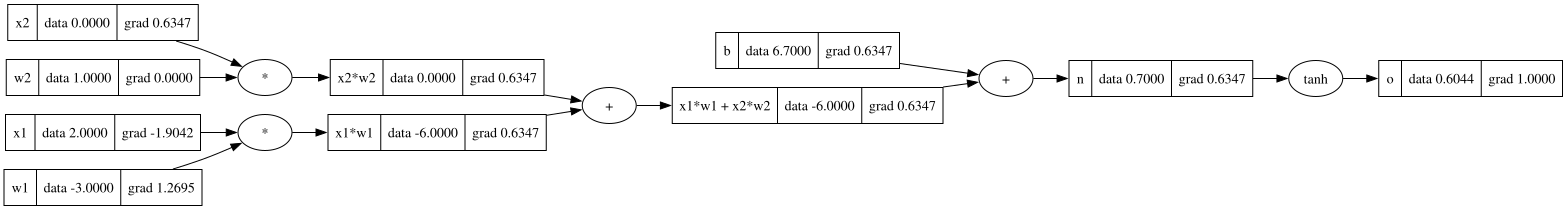

In [55]:
draw_dot(o)

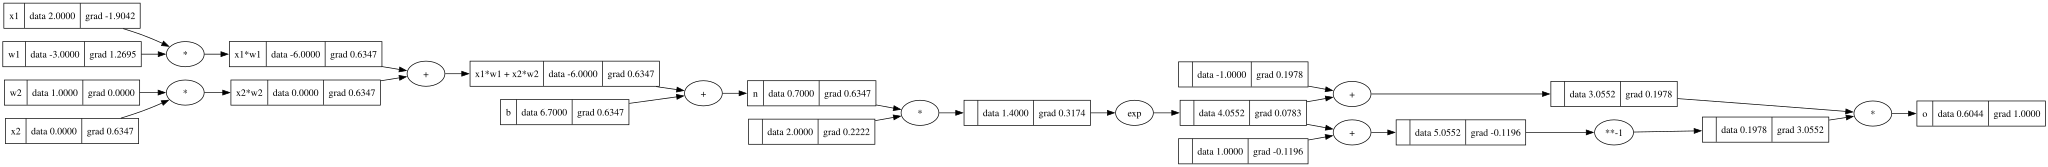

In [64]:
# Creation of a CSN231 neuron
# inputs x1, x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights w1, w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# the bias of the function
b = Value(6.7, label="b")

# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label="x1*w1"
x2w2 = x2*w2; x2w2.label="x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label="x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = "n"

# Add activation function
e = (2*n).exp()
o = (e - 1) / (e + 1)
o.label = ('o')
o.backward()
draw_dot(o)

In [9]:
o.grad = 1.0

In [11]:
o._backward()

In [13]:
n._backward()

In [15]:
b._backward()

In [17]:
x1w1x2w2._backward()

In [19]:
x1w1._backward()
x2w2._backward()

In [22]:
# build a topological list( to arrange the nodes from left to right)
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.7),
 Value(data=2.0),
 Value(data=-3.0),
 Value(data=-6.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=0.7000000000000002),
 Value(data=0.6043677771171636)]

In [28]:
# Try to reconstruct the backwards propagation through the use of the topological list
o.grad = 1.0

topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

for node in reversed(topo):
    node._backward()

In [8]:
import torch

In [9]:
x1 = torch.Tensor([2.0]).double()                ;x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ;x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ;w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ;w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ;b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('----')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
----
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [10]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # perform w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout): # number of inputs to receive and the number of neurons for a layer
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons] #for every neuron, put the inputs and then let's get the output produced
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        # params = []
        # for neuron in self.neurons:
        #     ps = neuron.parameters()
        #     parameters.extend(ps)
        
        
class MLP:
    def __init__(self, nin, nouts): # we now expect an array of number of neurons expected per layer
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return[p for layer in self.layers for p in layer.parameters()]


In [34]:
x = [2.0, 3.0]
# n = Neuron(2)
# n = Layer(2, 3)
n = MLP(2, [4, 4, 1])
n(x)
# draw_dot(n(x))

Value(data=0.09722746565106169)

In [35]:
n.parameters()

[Value(data=-0.0020785632130098097),
 Value(data=0.5082056905880634),
 Value(data=-0.30087148502874683),
 Value(data=-0.909433353795124),
 Value(data=0.17039515620864787),
 Value(data=-0.13194817913804435),
 Value(data=0.6262798459533461),
 Value(data=0.23088552497561055),
 Value(data=-0.3287846175959177),
 Value(data=0.44030620860406766),
 Value(data=-0.8914437665053232),
 Value(data=-0.18274966044741547),
 Value(data=0.6053373940182978),
 Value(data=0.6198630890609718),
 Value(data=-0.2880609609679736),
 Value(data=0.6604715024825658),
 Value(data=0.4356030017276582),
 Value(data=-0.045320464654914794),
 Value(data=0.5791847516815407),
 Value(data=0.33943825608565437),
 Value(data=-0.21359952185458608),
 Value(data=-0.8721516077337947),
 Value(data=0.8985290939382358),
 Value(data=-0.761842540780068),
 Value(data=-0.3597739792909165),
 Value(data=-0.579421188637331),
 Value(data=-0.8585106039386203),
 Value(data=-0.7334976688221058),
 Value(data=0.7596317433183963),
 Value(data=0.580

In [36]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0] # desired targets


In [37]:
ypred = [n(x) for x in xs]
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=7.107877952138118)

In [41]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
    
    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # Update
    for p in n.parameters():
        p.data += -0.05 * p.grad # put it as negative if you want to reduce the loss 0.01 is the learning rate

    print(k, loss.data)

0 3.493693968727878
1 0.8468165863887138
2 1.282887142944649
3 2.692952834148613
4 0.7903754153978964
5 1.5068718702986716
6 2.9005164191060047
7 3.082688117795012
8 0.48634359145861694
9 0.48040671968006343
10 0.5526610618063488
11 0.8893629706535336
12 1.8944482766615236
13 2.588833804540438
14 2.362490202413342
15 1.1702366841401137
16 1.9795570775916298
17 1.760946929408706
18 2.4705001298864
19 0.5605870751921594


In [42]:
ypred

[Value(data=0.8063126480947198),
 Value(data=-0.9025901743155779),
 Value(data=-0.9373073478331077),
 Value(data=0.28609997749790533)]